<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="../elementos/cabecalho_branco.jpg" alt="Cabeçalho" style="max-width: 100%; height: auto;">
</div>

# Distribuição binomial
### Monstro: Ogro

Autor: **Carlos Gabriel de Oliveira Campos**

Professor Dr. **Daniel Roberto Cassar**

"A distribuição binomial é a distribuição de probabilidade utilizada para modelar o número de *sucessos* em um número fixo de experimentos independentes com apenas dois resultados: sucesso ou falha. A distribuição é útil para calcular a probabilidade de um número específico de experimentos com sucesso em cenários como jogar moedas, controle de qualidade ou previsão de pesquisas de opinião." ([1], tradução própria). Essa distribuição pode ser visualizada discretamente por meio da função de massa de probabilidade, cuja sigla em inglês é *pmf*. Nesse caso, considera-se uma variável aleatória discreta, sendo que o gráfico da pmf mostra a probabilidade de determinadps resultados dessa variável [2].

---

## Exercícios

<h4> 1. Escolha um valor de 𝑝 tal que 0.2 ≤ 𝑝 ≤ 0.8. Com esse valor de 𝑝 constante, faça pelo menos 5 gráficos pmf da distribuição binomial com valores de 𝑛 diferentes. Escolha pelo menos um valor de 𝑛 próximo de 5 e pelo menos um valor de 𝑛 próximo de 100. Os gráficos devem apresentar todos os resultados do espaço amostral no eixo 𝑥 e respectivas probabilidades no eixo 𝑦. Escreva com suas palavras qual padrão você observa quando aumenta o valor de 𝑛. </h4>

In [3]:
import random
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom

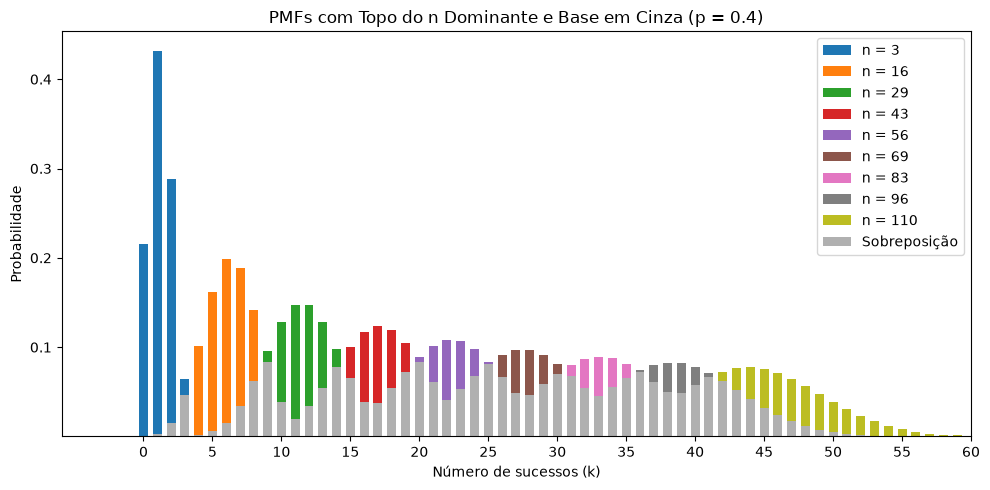

In [53]:
SEMENTE = 42
random.seed(SEMENTE)
intervalo = range(1,9)
p = random.choice(intervalo) / 10

lista_n = np.linspace(3, 110, num=9).astype('int')

    
p = 0.4
palette = plt.cm.tab10.colors

max_n = max(lista_n)
k_vals = np.arange(max_n + 1)

# Matriz (len(lista_n), len(k_vals))
prob_matrix = np.array([binom.pmf(k_vals, n, p) for n in lista_n])

fig, ax = plt.subplots(figsize=(10, 5))
largura = 0.65

# Altura máxima e segunda maior altura em cada k
max_heights = np.max(prob_matrix, axis=0)
vencedor_n = np.argmax(prob_matrix, axis=0)

# A altura compartilhada é o segundo maior valor (onde há sobreposição)
prob_sorted = np.sort(prob_matrix, axis=0)
segunda_altura = prob_sorted[-2, :]  # limite da sobreposição

# 1. Plota a base cinza comum
ax.bar(k_vals, segunda_altura, width=largura, color="#b0b0b0")

# 2. Plota apenas o topo excedente com a cor do n dominante
for i, n in enumerate(lista_n):
    # Máscara de onde este n foi o mais alto
    mask = vencedor_n == i
    topo = np.where(mask, max_heights - segunda_altura, 0)

    ax.bar(
        k_vals,
        topo,
        bottom=segunda_altura,
        width=largura,
        color=palette[i],
        label=f"n = {n}",
    )

# Entrada cinza para a legenda
ax.bar([0], [0], color="#b0b0b0", label="Sobreposição")

ax.set(
    xlabel="Número de sucessos (k)",
    ylabel="Probabilidade",
    title=f"PMFs com Topo do n Dominante e Base em Cinza (p = {p})",
)
ax.set_xticks(k_vals[::5])
ax.set_xlim(right=60)
ax.legend()
plt.tight_layout()
plt.show()

Esse gráfico evidencia claramente como a maior probabilidade observada para algum número $k$ de sucessos, dados $n$ possíveis resultados, tende a decrescer conforme $n$ aumenta. Isto é, se $p(k)$ representa a probabilidade de obter $k$ sucessos, então $p(k)$ mais provável para $n = 3$ é um pouco maior do que 0.4. Segue então que que a maior $p(k)$ para $n = 16$ é por volta de 0.2, e os seguintes valores de $p(k)$ para $n$ maiores continua decrescendo.  



Isso faz sentido, uma vez que a probabilidade de se obter $k$ sucessos é dada por 

$$
p(k) = \binom{n}{k} p^k (1-p)^{n-k}
$$

Pode ser provado matematicamente que para um determinado valor de $n$, $p(k)$ é maior para $k = np$. Assim, podemos formular o maior valor para $p(k)$ como
$$
p(np) = \binom{n}{np} p^{np} (1-p)^{n-np} = \binom{n}{np} p^{np} (1-p)^{n(1 - p)}
$$


Dado que $p < 1$, então $p^k < 1$, assim como $1 - p < 1$.

Dessa forma, como $(n - k) \in \{0, 1, 2, \dots, n\}$, logo $(1 - p)^{n - k} < 1$
, ou seja, conforme $n$ aumentar, então $np$ também aumentará. Assim,

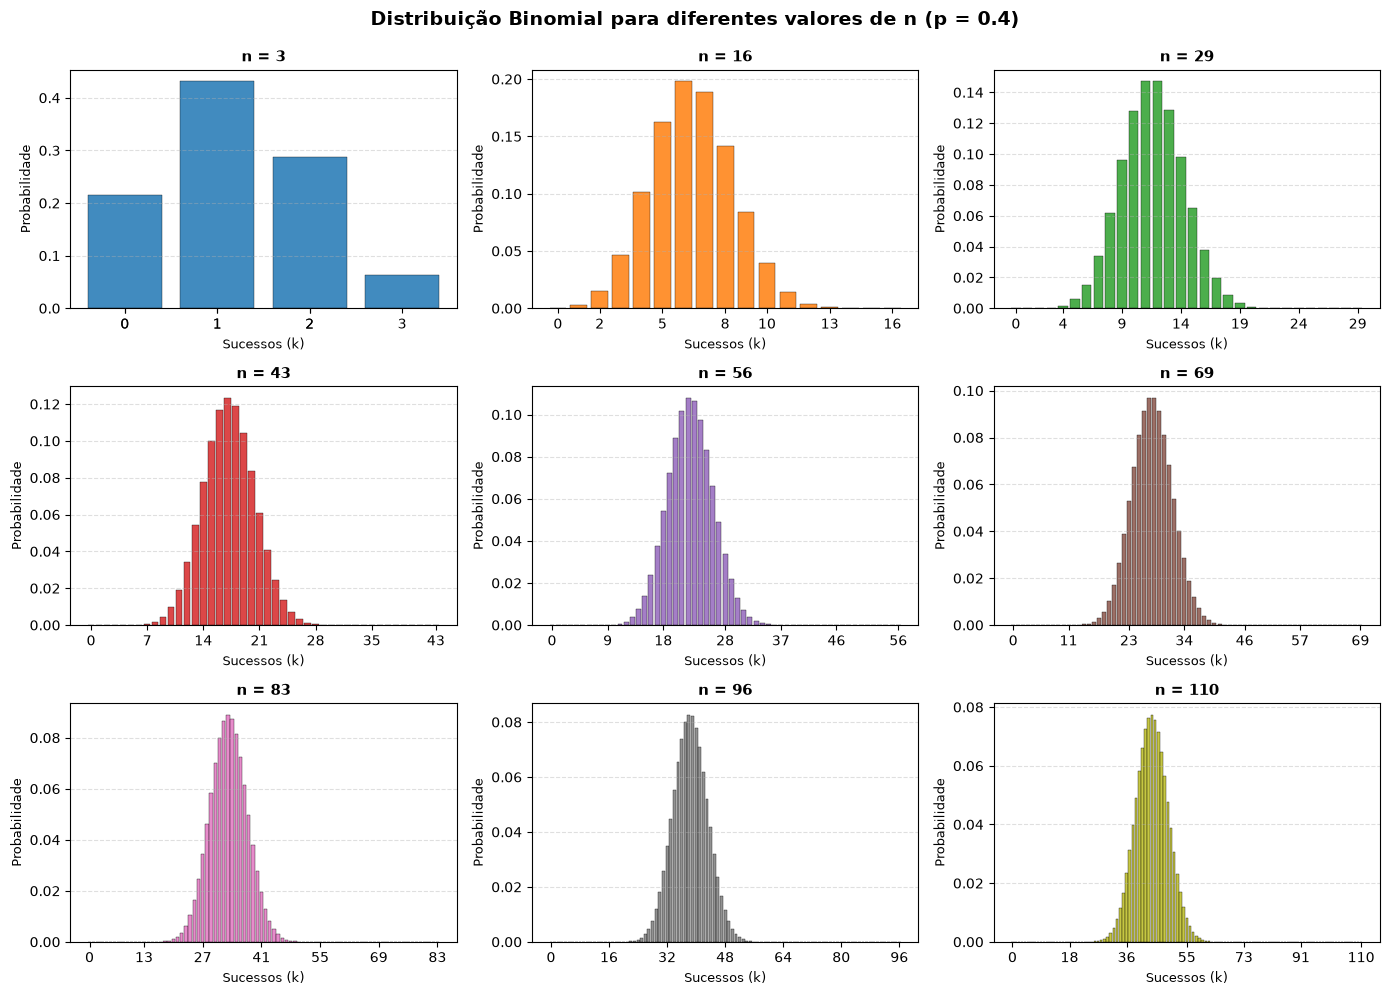

In [54]:
# 1. Configurações e sementes
random.seed(SEMENTE)
lista_n = np.linspace(3, 110, num=9).astype("int")
p = 0.4
palette = plt.cm.tab10.colors

# 2. Cria a figura com grid 3x3
fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharey=False)
axes = axes.flatten()  # Transforma a matriz 3x3 em um vetor de 9 eixos

# 3. Plota cada distribuição em seu respectivo subplot
for i, n in enumerate(lista_n):
    ax = axes[i]
    k_vals = np.arange(n + 1)
    pmf_vals = binom.pmf(k_vals, n, p)

    # Barras individuais para cada n
    ax.bar(
        k_vals,
        pmf_vals,
        color=palette[i % len(palette)],
        width=0.8,
        edgecolor="black",
        linewidth=0.3,
        alpha=0.85,
    )

    xticks = np.linspace(0, n, num=7).astype('int')
    ax.set_xticks(xticks)
    ax.set_title(f"n = {n}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Sucessos (k)", fontsize=9)
    ax.set_ylabel("Probabilidade", fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle(
    f"Distribuição Binomial para diferentes valores de n (p = {p})",
    fontsize=14,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout()
plt.show()

Já o segundo gráfico revela que quanto maior o valor de $n$, a *pmf* (função de massa de probabilidade)  tende a ficar mais simétrica. Seguindo a mesma tendência, a "dispersão das probabilidades" tende a ser menor, visto que para valores de $k$ mais afastados de $np$, $p(k)$ tende a representar uma fração cada vez menor da maior probabilidade. Dessa forma, os maiores valores de probabilidade tendem a ficar mais concentrados nas proximidades de $k = np$, ao passo que $p(k)$ torna-se ínfimo para valores de $k$ "periféricos". 

<h4> 2. Escolha um valor de 𝑛 fixo (algo entre 20 e 50). Com esse valor de 𝑛 constante, faça pelo menos 5 gráficos pmf da distribuição binomial variando 𝑝 entre 0.1 e 0.9. Observe e discuta como o formato e a posição do pico da distribuição mudam conforme 𝑝 se aproxima de 0 ou 1, e o que ocorre quando 𝑝 = 0.5. Os cálculos das probabilidades da pmf podem ser feitos da maneira que desejar. No entanto, é recomendado aproveitar essa tarefa para aprender a utilizar o scipy para realizar estes cálculos. </h4>

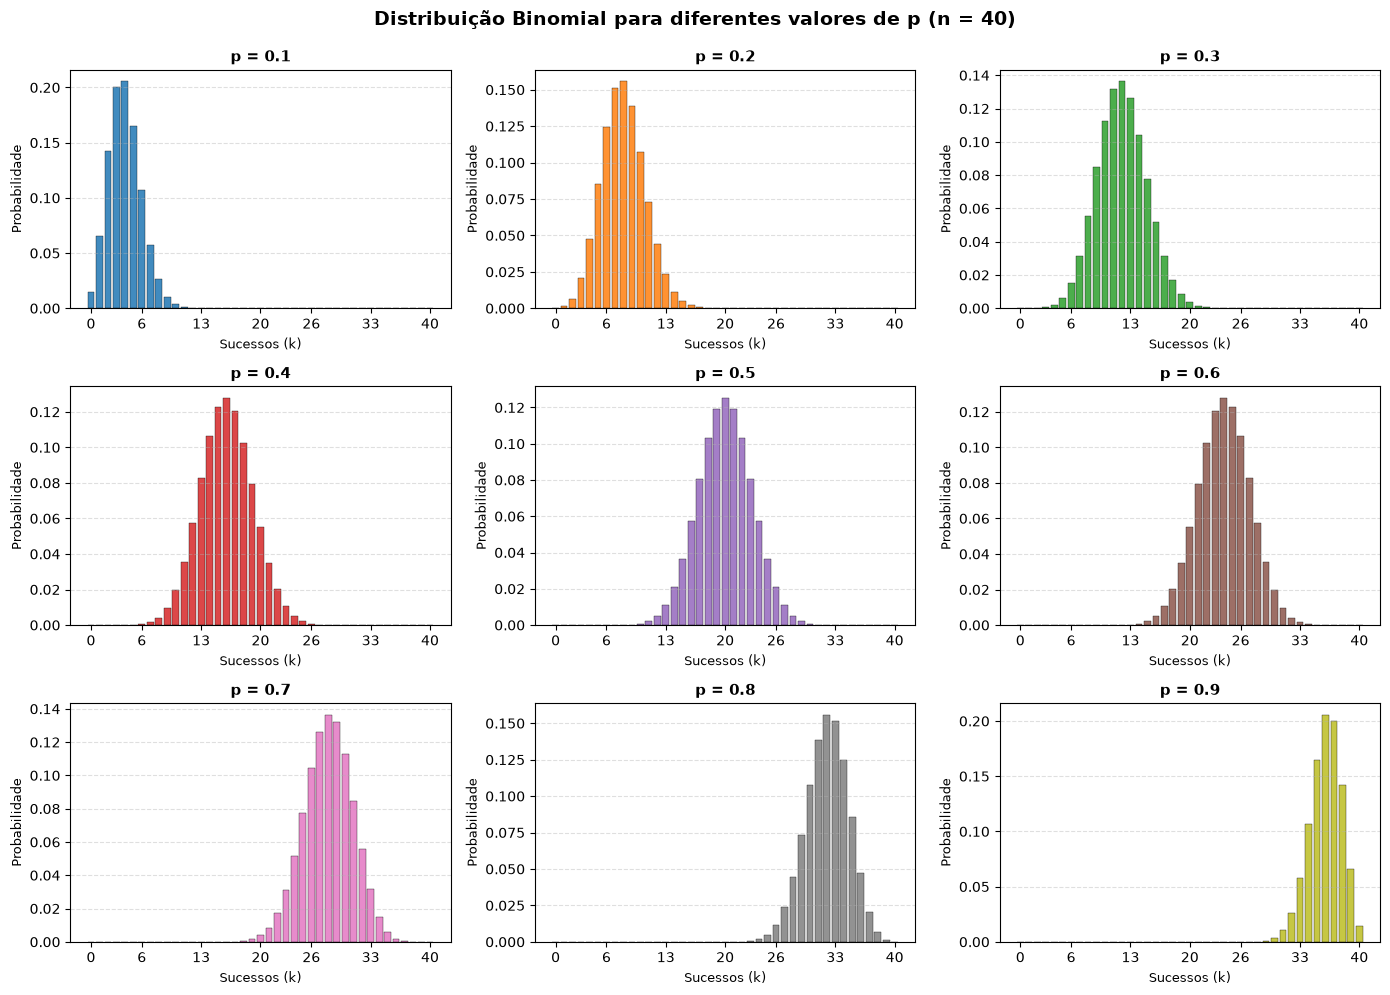

In [55]:
random.seed(SEMENTE)
intervalo = range(20,51)
n = random.choice(intervalo) # n = 40
lista_p = np.arange(1, 10) / 10

palette = plt.cm.tab10.colors

# 2. Cria a figura com grid 3x3
fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharey=False)
axes = axes.flatten()  # Transforma a matriz 3x3 em um vetor de 9 eixos

# 3. Plota cada distribuição em seu respectivo subplot
for i, p in enumerate(lista_p):
    ax = axes[i]
    k_vals = np.arange(n + 1)
    pmf_vals = binom.pmf(k_vals, n, p)

    # Barras individuais para cada n
    ax.bar(
        k_vals,
        pmf_vals,
        color=palette[i % len(palette)],
        width=0.8,
        edgecolor="black",
        linewidth=0.3,
        alpha=0.85,
    )

    xticks = np.linspace(0, n, num=7).astype('int')
    ax.set_xticks(xticks)
    ax.set_title(f"p = {p}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Sucessos (k)", fontsize=9)
    ax.set_ylabel("Probabilidade", fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle(
    f"Distribuição Binomial para diferentes valores de p (n = {n})",
    fontsize=14,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout()
plt.show()

Tendo fixado $n$, observa-se que a variação de $p$ causa um deslocamento na distribuição das probabilidades correspondente. Logicamente, uma menor probabilidade de sucesso $p$ torna um maior número de sucessos mais escasso, enquanto que valores menos expressivos de $k$ predominam. Desse modo, o inverso também é verdadeiro. 

Retomando o que foi comentado previamente, isso é congruente com o fato de que $k \to np$ implica em uma maior $p(k).$ Portanto, é previsível que a mudança de $p$ reverbere dessa forma sobre a pmf. 

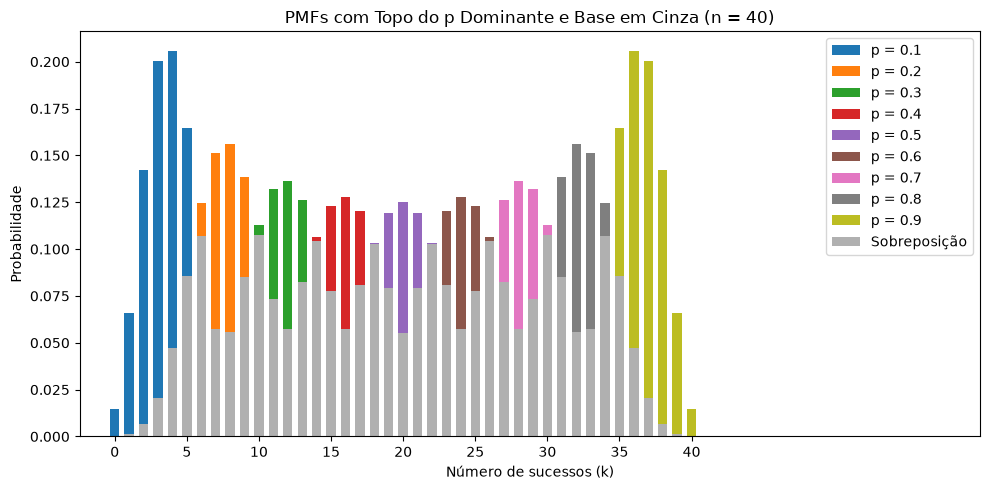

In [56]:
intervalo = range(20,51)
random.seed(SEMENTE)
n = random.choice(intervalo) # n = 40

lista_p = np.linspace(1, 9, num=9) / 10

palette = plt.cm.tab10.colors

k_vals = np.arange(n + 1)

# Matriz (len(lista_p), len(k_vals))
prob_matrix = np.array([binom.pmf(k_vals, n, p) for p in lista_p])

fig, ax = plt.subplots(figsize=(10, 5))
largura = 0.65

# Altura máxima e segunda maior altura em cada k
max_heights = np.max(prob_matrix, axis=0)
vencedor_n = np.argmax(prob_matrix, axis=0)

# A altura compartilhada é o segundo maior valor (onde há sobreposição)
prob_sorted = np.sort(prob_matrix, axis=0)
segunda_altura = prob_sorted[-2, :]  # limite da sobreposição

# 1. Plota a base cinza comum
ax.bar(k_vals, segunda_altura, width=largura, color="#b0b0b0")

# 2. Plota apenas o topo excedente com a cor do n dominante
for i, p in enumerate(lista_p):
    # Máscara de onde este n foi o mais alto
    mask = vencedor_n == i
    topo = np.where(mask, max_heights - segunda_altura, 0)

    ax.bar(
        k_vals,
        topo,
        bottom=segunda_altura,
        width=largura,
        color=palette[i],
        label=f"p = {p}",
    )

# Entrada cinza para a legenda
ax.bar([0], [0], color="#b0b0b0", label="Sobreposição")

ax.set(
    xlabel="Número de sucessos (k)",
    ylabel="Probabilidade",
    title=f"PMFs com Topo do p Dominante e Base em Cinza (n = {n})",
)
ax.set_xticks(k_vals[::5])
ax.set_xlim(right=60)
ax.legend()
plt.tight_layout()
plt.show()

Por fim, esse gráfico complementa a última descrição, mostrando as diferentes pmfs lado a lado. Essa apresentação revela um padrão de curva entre os máximos valores de cada pmf, sendo que pmfs das extremidades destacam-se com os maiores picos, enquanto o conjunto das pmfs centrais formam um vale com uma suave inclinação.

## Conclusão

A função de massa de probabilidade demonstrou-se ser uma ferrmaneta útil para visualizar a distribuição binomial. Essa ferramenta nos possibilitou observar as mudanças geradas nas distribuições binomiais a partir da variação de parâmetros da distribuição, como o número de experimentos $n$ e a probabilidade de sucesso $p$.

## Uso de IA neste trabalho


A ferramenta de inteligência artificial Gemini foi utilizada para auxiliar a:

- Plotar gráficos;
- Compreender melhor a função de massa de probabilidade
- Compreender o código para aplicar binom.pmf.

## Referências

[1] **Binomial Distribution in Probability**. GeeksforGeeks, 7 jul. 2026. Disponível em: https://www.geeksforgeeks.org/maths/binomial-distribution/. Acesso em: 22 set. 2026.

[2] CASSAR, Daniel R. Material de aula **LMA-203 6.0 - Distribuição de probabilidades discretas**. para a disciplina de Estatística, 2026.

<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="../elementos/rodape_eleicao.png" alt="Rodapé" style="max-width: 100%; height: auto;">
</div>